In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [2]:
data = {
    "Motion": [1,1,1,1,0,0,0,0,1,1,1,0,1,1,0,0,
               1,1,1,0,0,1,1,0,1,1,0,0,1,1],

    "Door": [0,1,0,0,0,0,0,0,1,0,1,0,0,1,0,0,
             1,0,1,0,0,1,0,0,1,0,0,0,1,0],

    "Light": [1,1,1,1,0,0,0,0,1,1,1,0,1,1,0,0,
              1,1,1,0,0,1,1,0,1,1,0,0,1,1],

    "Temperature": [25,25.5,26,26.5,22,22.2,22.1,21.8,
                    24,24.5,25,22.5,26,26.5,22,21.5,
                    24,24.5,25,22,22.2,25,25.5,22,
                    26,26.5,22,21.8,24,24.5],

    "Activity": [
        "Cooking","Cooking","Cooking","Cooking",
        "Sleeping","Sleeping","Sleeping","Sleeping",
        "Walking","Walking","Walking","Sleeping",
        "Cooking","Cooking","Sleeping","Sleeping",
        "Walking","Walking","Walking","Sleeping",
        "Sleeping","Cooking","Cooking","Sleeping",
        "Cooking","Cooking","Sleeping","Sleeping",
        "Walking","Walking"
    ]
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print(df.head())

Dataset created successfully!
   Motion  Door  Light  Temperature  Activity
0       1     0      1         25.0   Cooking
1       1     1      1         25.5   Cooking
2       1     0      1         26.0   Cooking
3       1     0      1         26.5   Cooking
4       0     0      0         22.0  Sleeping


In [3]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)

print("\nActivity Classes:")
print(df["Activity"].unique())

print("\nActivity Counts:")
print(df["Activity"].value_counts())

Dataset Shape: (30, 5)

Column Names:
Index(['Motion', 'Door', 'Light', 'Temperature', 'Activity'], dtype='object')

Activity Classes:
['Cooking' 'Sleeping' 'Walking']

Activity Counts:
Activity
Sleeping    12
Cooking     10
Walking      8
Name: count, dtype: int64


In [4]:
label_encoder = LabelEncoder()

df["Activity_Encoded"] = label_encoder.fit_transform(df["Activity"])

print(df[["Activity", "Activity_Encoded"]].drop_duplicates())

   Activity  Activity_Encoded
0   Cooking                 0
4  Sleeping                 1
8   Walking                 2


In [5]:
features = ["Motion", "Door", "Light", "Temperature"]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(df[features])

print("Normalized Sensor Data:")
print(X_scaled[:5])

Normalized Sensor Data:
[[ 0.81649658 -0.65465367  0.81649658  0.62032562]
 [ 0.81649658  1.52752523  0.81649658  0.91201478]
 [ 0.81649658 -0.65465367  0.81649658  1.20370395]
 [ 0.81649658 -0.65465367  0.81649658  1.49539311]
 [-1.22474487 -0.65465367 -1.22474487 -1.12980936]]


In [6]:
sequence_length = 5

X = []
y = []

for i in range(len(X_scaled) - sequence_length + 1):
    X.append(X_scaled[i:i + sequence_length])
    y.append(df["Activity_Encoded"].iloc[i + sequence_length - 1])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (26, 5, 4)
y shape: (26,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

Training data: (20, 5, 4)
Testing data : (6, 5, 4)


In [8]:
model = Sequential()

model.add(LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dropout(0.2))

model.add(Dense(32, activation="relu"))

model.add(Dense(3, activation="softmax"))

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,843 (77.51 KB)

 Trainable params: 19,843 (77.51 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=4,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - accuracy: 0.3500 - loss: 1.0921 - val_accuracy: 0.3333 - val_loss: 1.0756
Epoch 2/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5500 - loss: 1.0474 - val_accuracy: 0.6667 - val_loss: 1.0354
Epoch 3/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7500 - loss: 1.0080 - val_accuracy: 0.6667 - val_loss: 0.9988
Epoch 4/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7000 - loss: 0.9767 - val_accuracy: 0.6667 - val_loss: 0.9618
Epoch 5/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6500 - loss: 0.9335 - val_accuracy: 0.6667 - val_loss: 0.9233
Epoch 6/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6500 - loss: 0.8822 - val_accuracy: 0.5000 - val_loss: 0.8864
Epoch 7/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7000 - loss: 0.8402 - val_accuracy: 0.8333 - val_loss: 0.8460
Epoch 8/50
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7000 - loss: 0.7892 - val_accuracy: 0.8333 - val_loss: 0.8050


In [10]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

Test Loss: 0.2639874517917633
Test Accuracy: 0.8333333134651184
Test Accuracy (%): 83.33333134651184


In [11]:
y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Actual Activities:")
print(label_encoder.inverse_transform(y_test))

print("\nPredicted Activities:")
print(label_encoder.inverse_transform(y_pred))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 255ms/step
Actual Activities:
['Walking' 'Sleeping' 'Sleeping' 'Walking' 'Cooking' 'Sleeping']

Predicted Activities:
['Walking' 'Sleeping' 'Sleeping' 'Cooking' 'Cooking' 'Sleeping']


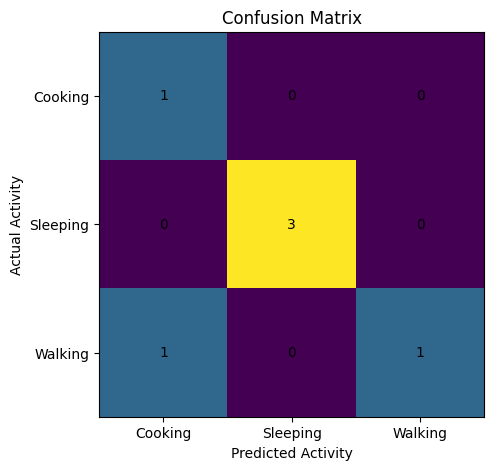

In [12]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Activity")
plt.ylabel("Actual Activity")

plt.xticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_
)

plt.yticks(
    range(len(label_encoder.classes_)),
    label_encoder.classes_
)

for i in range(len(cm)):
    for j in range(len(cm)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

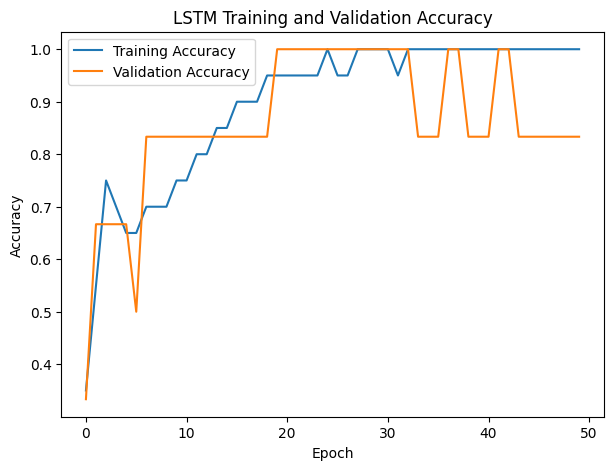

In [13]:
plt.figure(figsize=(7, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training and Validation Accuracy")
plt.legend()

plt.show()

In [14]:
def predict_activity(motion, door, light, temperature):

    # Create 5 time steps
    new_data = pd.DataFrame([
        [motion, door, light, temperature],
        [motion, door, light, temperature],
        [motion, door, light, temperature],
        [motion, door, light, temperature],
        [motion, door, light, temperature]
    ], columns=features)

    # Normalize sensor values
    new_data_scaled = scaler.transform(new_data)

    # Convert to LSTM input shape
    new_sequence = new_data_scaled.reshape(1, 5, 4)

    # Predict
    prediction = model.predict(new_sequence, verbose=0)

    predicted_class = np.argmax(prediction)
    confidence = np.max(prediction) * 100

    activity = label_encoder.inverse_transform(
        [predicted_class]
    )[0]

    print("----- LIVE ACTIVITY PREDICTION -----")
    print("Motion       :", motion)
    print("Door         :", door)
    print("Light        :", light)
    print("Temperature  :", temperature)
    print("------------------------------------")
    print("Predicted Activity:", activity)
    print("Confidence:", round(confidence, 2), "%")

In [15]:
import ipywidgets as widgets
from IPython.display import display

# Create input boxes
motion_input = widgets.IntSlider(
    value=1,
    min=0,
    max=1,
    step=1,
    description="Motion:"
)

door_input = widgets.IntSlider(
    value=0,
    min=0,
    max=1,
    step=1,
    description="Door:"
)

light_input = widgets.IntSlider(
    value=1,
    min=0,
    max=1,
    step=1,
    description="Light:"
)

temperature_input = widgets.FloatSlider(
    value=25,
    min=15,
    max=35,
    step=0.5,
    description="Temp:"
)

predict_button = widgets.Button(
    description="Predict Activity",
    button_style="success"
)

output = widgets.Output()

def on_predict(button):

    with output:
        output.clear_output()

        predict_activity(
            motion_input.value,
            door_input.value,
            light_input.value,
            temperature_input.value
        )

predict_button.on_click(on_predict)

display(
    motion_input,
    door_input,
    light_input,
    temperature_input,
    predict_button,
    output
)

IntSlider(value=1, description='Motion:', max=1)

IntSlider(value=0, description='Door:', max=1)

IntSlider(value=1, description='Light:', max=1)

FloatSlider(value=25.0, description='Temp:', max=35.0, min=15.0, step=0.5)

Button(button_style='success', description='Predict Activity', style=ButtonStyle())

Output()

In [16]:
import numpy as np
import pandas as pd

np.random.seed(42)

rows = []

# Generate 1000 sensor readings
for i in range(1000):

    activity = np.random.choice(
        ["Cooking", "Sleeping", "Walking"]
    )

    if activity == "Cooking":
        motion = np.random.choice([0, 1], p=[0.1, 0.9])
        door = np.random.choice([0, 1], p=[0.7, 0.3])
        light = 1
        temperature = np.random.normal(26, 1)

    elif activity == "Sleeping":
        motion = 0
        door = 0
        light = 0
        temperature = np.random.normal(22, 1)

    else:  # Walking
        motion = 1
        door = np.random.choice([0, 1])
        light = np.random.choice([0, 1])
        temperature = np.random.normal(24, 1)

    rows.append([
        motion,
        door,
        light,
        temperature,
        activity
    ])

df = pd.DataFrame(
    rows,
    columns=[
        "Motion",
        "Door",
        "Light",
        "Temperature",
        "Activity"
    ]
)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

print("\nActivity distribution:")
print(df["Activity"].value_counts())

Dataset created successfully!
Dataset shape: (1000, 5)

First 5 rows:
   Motion  Door  Light  Temperature  Activity
0       1     1      0    24.543743   Walking
1       1     0      1    25.384570   Cooking
2       1     0      1    23.114770   Walking
3       1     1      0    23.587812   Walking
4       0     0      0    22.233095  Sleeping

Activity distribution:
Activity
Cooking     352
Sleeping    334
Walking     314
Name: count, dtype: int64


In [17]:
# Select sensor features
features = ["Motion", "Door", "Light", "Temperature"]

# Encode activity labels
label_encoder = LabelEncoder()
df["Activity_Encoded"] = label_encoder.fit_transform(df["Activity"])

# Normalize sensor values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

# Target values
y_raw = df["Activity_Encoded"].values

print("Features:", features)
print("Activities:", label_encoder.classes_)
print("Scaled data shape:", X_scaled.shape)

Features: ['Motion', 'Door', 'Light', 'Temperature']
Activities: [np.str_('Cooking') np.str_('Sleeping') np.str_('Walking')]
Scaled data shape: (1000, 4)


In [18]:
sequence_length = 10

X = []
y = []

for i in range(len(X_scaled) - sequence_length + 1):
    X.append(X_scaled[i:i + sequence_length])
    y.append(y_raw[i + sequence_length - 1])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (991, 10, 4)
y shape: (991,)


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

Training data: (792, 10, 4)
Testing data : (199, 10, 4)


In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential()

# LSTM layer
model.add(
    LSTM(
        64,
        input_shape=(X_train.shape[1], X_train.shape[2])
    )
)

# Dropout to reduce overfitting
model.add(Dropout(0.2))

# Fully connected layer
model.add(Dense(32, activation="relu"))

# Output layer
model.add(Dense(3, activation="softmax"))

# Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,843 (77.51 KB)

 Trainable params: 19,843 (77.51 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.5051 - loss: 1.0427 - val_accuracy: 0.6683 - val_loss: 0.9596
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6591 - loss: 0.8569 - val_accuracy: 0.7286 - val_loss: 0.7150
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7891 - loss: 0.5676 - val_accuracy: 0.8894 - val_loss: 0.3869
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8725 - loss: 0.3623 - val_accuracy: 0.9196 - val_loss: 0.2685
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9129 - loss: 0.2713 - val_accuracy: 0.9196 - val_loss: 0.2173
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9205 - loss: 0.2241 - val_accuracy: 0.9246 - val_loss: 0.1913
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9331 - loss: 0.1947 - val_accuracy: 0.9196 - val_loss: 0.1857
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9331 - loss: 0.1878 - val_accuracy: 0.9246 - val_

In [22]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(accuracy, 4))
print("Test Accuracy (%):", round(accuracy * 100, 2), "%")

Test Loss: 0.2085
Test Accuracy: 0.9045
Test Accuracy (%): 90.45 %


In [23]:
y_pred_prob = model.predict(X_test, verbose=0)

y_pred = np.argmax(y_pred_prob, axis=1)

actual = label_encoder.inverse_transform(y_test)
predicted = label_encoder.inverse_transform(y_pred)

comparison = pd.DataFrame({
    "Actual Activity": actual,
    "Predicted Activity": predicted
})

print(comparison.head(20))

   Actual Activity Predicted Activity
0          Cooking            Cooking
1          Cooking            Cooking
2         Sleeping           Sleeping
3         Sleeping           Sleeping
4          Cooking            Cooking
5          Cooking            Cooking
6         Sleeping           Sleeping
7          Cooking            Cooking
8         Sleeping           Sleeping
9          Walking            Walking
10         Cooking            Walking
11         Cooking            Walking
12         Walking            Walking
13         Cooking            Cooking
14        Sleeping           Sleeping
15         Cooking            Cooking
16         Walking            Cooking
17        Sleeping           Sleeping
18        Sleeping           Sleeping
19        Sleeping           Sleeping


In [24]:
print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

              precision    recall  f1-score   support

     Cooking       0.89      0.83      0.86        70
    Sleeping       1.00      1.00      1.00        67
     Walking       0.82      0.89      0.85        62

    accuracy                           0.90       199
   macro avg       0.90      0.91      0.90       199
weighted avg       0.91      0.90      0.90       199



In [25]:
import ipywidgets as widgets
from IPython.display import display

# Sensor input sliders
motion_input = widgets.IntSlider(
    value=1, min=0, max=1, step=1,
    description="Motion:"
)

door_input = widgets.IntSlider(
    value=1, min=0, max=1, step=1,
    description="Door:"
)

light_input = widgets.IntSlider(
    value=1, min=0, max=1, step=1,
    description="Light:"
)

temperature_input = widgets.FloatSlider(
    value=26, min=18, max=32, step=0.5,
    description="Temp:"
)

predict_button = widgets.Button(
    description="Predict Activity",
    button_style="success"
)

output = widgets.Output()


def live_prediction(button):

    with output:
        output.clear_output()

        # Get current sensor values
        new_data = pd.DataFrame(
            [[
                motion_input.value,
                door_input.value,
                light_input.value,
                temperature_input.value
            ]] * 10,
            columns=features
        )

        # Normalize
        new_data_scaled = scaler.transform(new_data)

        # Convert to LSTM sequence
        new_sequence = new_data_scaled.reshape(1, 10, 4)

        # Prediction
        prediction = model.predict(
            new_sequence,
            verbose=0
        )

        predicted_class = np.argmax(prediction)
        confidence = np.max(prediction) * 100

        activity = label_encoder.inverse_transform(
            [predicted_class]
        )[0]

        print("===================================")
        print("   SMART HOME ACTIVITY RECOGNIZER")
        print("===================================")

        print("Motion       :", motion_input.value)
        print("Door         :", door_input.value)
        print("Light        :", light_input.value)
        print("Temperature  :", temperature_input.value)

        print("-----------------------------------")

        print("Predicted Activity :", activity)
        print("Confidence         :", round(confidence, 2), "%")


predict_button.on_click(live_prediction)

display(
    motion_input,
    door_input,
    light_input,
    temperature_input,
    predict_button,
    output
)

IntSlider(value=1, description='Motion:', max=1)

IntSlider(value=1, description='Door:', max=1)

IntSlider(value=1, description='Light:', max=1)

FloatSlider(value=26.0, description='Temp:', max=32.0, min=18.0, step=0.5)

Button(button_style='success', description='Predict Activity', style=ButtonStyle())

Output()